# Boiler Sensor Seasonality and Trend Checks

This notebook checks trends and recurring patterns in `data.csv` and `data_AutoReg.csv`, using `columns.csv` for sensor labels and `EDA.ipynb` for prior data-quality context. Results are exploratory descriptions, not causal explanations or operating limits. The supplied records cover only a few days; this is enough to inspect short-term patterns, but not enough to establish a reliable weekly or longer-term seasonal cycle.

In [1]:
from pathlib import Path
import json
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display

sns.set_theme(style="whitegrid", context="notebook")
pd.set_option("display.max_columns", 40)
pd.set_option("display.max_rows", 30)

def find_project_root(start=None):
    start = Path.cwd() if start is None else Path(start)
    for folder in (start, *start.parents):
        if all((folder / name).is_file() for name in (
            "columns.csv", "data.csv", "data_AutoReg.csv", "EDA.ipynb"
        )):
            return folder
    raise FileNotFoundError(
        "Could not locate columns.csv, both data CSVs, and EDA.ipynb from the current directory or its parents."
    )

PROJECT_DIR = find_project_root()
print(f"Project directory: {PROJECT_DIR}")

Project directory: c:\Users\sulaiman.at\Documents\GitHub\Industrial-Boiler-Operations-Analytics


## 1. Load datasets, descriptions, and EDA context

CSV timestamps are parsed with coercion so bad values can be counted. Measurement headers ending in `#` are normalized for metadata matching only; original columns are preserved. In this repository `columns.csv` contains the sensor names in `Attribute name`, while `Description` is blank for these entries, so the notebook uses the available attribute name.

In [2]:
def canonical_name(value):
    return str(value).removesuffix("#")

metadata = pd.read_csv(PROJECT_DIR / "columns.csv")
data = pd.read_csv(PROJECT_DIR / "data.csv")
autoreg = pd.read_csv(PROJECT_DIR / "data_AutoReg.csv")

for frame in (data, autoreg):
    if "date" not in frame.columns:
        raise ValueError("Both observation datasets must include a 'date' column.")
    frame["date"] = pd.to_datetime(frame["date"], errors="coerce")

if "Variant" not in metadata.columns:
    raise ValueError("columns.csv must contain a 'Variant' column.")
descriptions = metadata.get("Description", pd.Series(index=metadata.index, dtype="object"))
descriptions = descriptions.fillna("").astype(str).str.strip()
if "Attribute name" in metadata.columns:
    descriptions = descriptions.where(
        descriptions.ne(""), metadata["Attribute name"].fillna("").astype(str).str.strip()
    )
metadata_map = dict(zip(metadata["Variant"].map(canonical_name), descriptions))

with (PROJECT_DIR / "EDA.ipynb").open(encoding="utf-8") as file:
    eda_notebook = json.load(file)
eda_headings = [
    line[3:].strip()
    for cell in eda_notebook.get("cells", []) if cell.get("cell_type") == "markdown"
    for line in cell.get("source", []) if line.startswith("## ")
]
print("EDA sections informing this analysis:")
for heading in eda_headings:
    print(f"- {heading}")
display(pd.DataFrame({"data.csv": data.shape, "data_AutoReg.csv": autoreg.shape}, index=["rows", "columns"]).T)
print(f"Metadata sensor entries: {len(metadata_map)}")
display(metadata.head())

EDA sections informing this analysis:
- 1. Load the datasets
- 2. Schema and measurement descriptions
- 3. Data quality and time coverage
- 4. Descriptive statistics
- 5. Compare the two observation files
- 6. Visual exploration
- 7. Automatically generated observations


,rows,columns
data.csv,86400,31
data_AutoReg.csv,86400,31


Metadata sensor entries: 30


,Variant,Attribute name,Description
0,PT_8313A.AV_0,Upper furnace pressure (A),NaN
1,PT_8313B.AV_0,Upper furnace pressure (B),NaN
2,PT_8313C.AV_0,Upper furnace pressure (C),NaN
3,PT_8313D.AV_0,Upper furnace pressure (D),NaN
4,PT_8313E.AV_0,Upper furnace pressure (E),NaN


## 2. Timestamp coverage, cadence, and observable cycles

Seasonality needs multiple repetitions to be credible. This section checks timestamp ordering, duplicates, coverage, and median cadence. It counts how many nominal cycles each possible period would have in the available span; a weekly cycle cannot be established from a record shorter than one week, and even one observed cycle is not enough to confirm repeatability.

In [3]:
PERIODS = {
    "hourly": pd.Timedelta(hours=1),
    "daily": pd.Timedelta(days=1),
    "weekly": pd.Timedelta(days=7),
}

def time_report(frame, name):
    timestamps = frame["date"]
    valid = timestamps.dropna()
    print(f"### {name}")
    print(f"Rows: {len(frame):,}; invalid timestamps: {timestamps.isna().sum():,}; "
          f"duplicate timestamps: {valid.duplicated().sum():,}")
    if valid.empty:
        print("No valid timestamps available.\n")
        return None
    ordered = valid.sort_values()
    span = ordered.max() - ordered.min()
    intervals = ordered.diff().dropna().dt.total_seconds()
    cadence = intervals.median() if not intervals.empty else np.nan
    print(f"Coverage: {ordered.min()} to {ordered.max()} ({span})")
    print(f"Chronological in source order: {valid.is_monotonic_increasing}; "
          f"median interval: {cadence:g} seconds")
    rows = []
    for label, period in PERIODS.items():
        count = span / period
        rows.append({"cycle": label, "period": period, "cycles_in_span": count,
                     "two_or_more_cycles": count >= 2})
    display(pd.DataFrame(rows))
    print()
    return {"start": ordered.min(), "end": ordered.max(), "span": span, "cadence_seconds": cadence}

time_info = {
    "data.csv": time_report(data, "data.csv"),
    "data_AutoReg.csv": time_report(autoreg, "data_AutoReg.csv"),
}

numeric_data_cols = data.select_dtypes(include="number").columns.tolist()
numeric_autoreg_cols = autoreg.select_dtypes(include="number").columns.tolist()
print(f"Numeric measurement columns: data.csv={len(numeric_data_cols)}, "
      f"data_AutoReg.csv={len(numeric_autoreg_cols)}")

### data.csv
Rows: 86,400; invalid timestamps: 0; duplicate timestamps: 0
Coverage: 2022-03-27 14:28:54 to 2022-04-01 14:28:49 (4 days 23:59:55)
Chronological in source order: True; median interval: 5 seconds


,cycle,period,cycles_in_span,two_or_more_cycles
0,hourly,0 days 01:00:00,119.998611,True
1,daily,1 days 00:00:00,4.999942,True
2,weekly,7 days 00:00:00,0.714277,False



### data_AutoReg.csv
Rows: 86,400; invalid timestamps: 0; duplicate timestamps: 0
Coverage: 2022-03-27 14:28:54 to 2022-04-01 14:28:49 (4 days 23:59:55)
Chronological in source order: True; median interval: 5 seconds


,cycle,period,cycles_in_span,two_or_more_cycles
0,hourly,0 days 01:00:00,119.998611,True
1,daily,1 days 00:00:00,4.999942,True
2,weekly,7 days 00:00:00,0.714277,False



Numeric measurement columns: data.csv=30, data_AutoReg.csv=30


## 3. Resample to minute-level summaries

The source appears to be sampled every five seconds, so minute means reduce noise and the workload while retaining operational changes on a practical timescale. This resampling smooths sub-minute behavior and cannot be used to assess fast transients. Duplicate records within a minute are naturally averaged.

In [4]:
def minute_means(frame):
    numeric_cols = frame.select_dtypes(include="number").columns.tolist()
    valid = frame.dropna(subset=["date"])
    if not numeric_cols or valid.empty:
        return pd.DataFrame()
    return (valid.set_index("date")[numeric_cols]
            .resample("1min").mean())

minute_data = minute_means(data)
minute_autoreg = minute_means(autoreg)
print(f"Minute-mean rows: data.csv={len(minute_data):,}; data_AutoReg.csv={len(minute_autoreg):,}")
display(minute_data.head())

Minute-mean rows: data.csv=7,201; data_AutoReg.csv=7,201


,PT_8313A.AV_0#,PT_8313B.AV_0#,PT_8313C.AV_0#,PT_8313D.AV_0#,PT_8313E.AV_0#,PT_8313F.AV_0#,PTCA_8322A.AV_0#,PTCA_8324.AV_0#,TE_8319A.AV_0#,TE_8319B.AV_0#,TE_8313B.AV_0#,TE_8303.AV_0#,TE_8304.AV_0#,TV_8329ZC.AV_0#,FT_8301.AV_0#,FT_8302.AV_0#,FT_8306A.AV_0#,AIR_8301A.AV_0#,FT_8306B.AV_0#,AIR_8301B.AV_0#,YFJ3_AI.AV_0#,YFJ3_ZD1.AV_0#,YFJ3_ZD2.AV_0#,SXLTCYZ.AV_0#,SXLTCYY.AV_0#,ZCLCCY.AV_0#,YCLCCY.AV_0#,YJJWSLL.AV_0#,ZZQBCHLL.AV_0#,TE_8332A.AV_0#
date,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,
2022-03-27 14:28:00,-142.535000,-183.235000,-150.005000,-107.705000,-138.970000,-150.965000,9.700000,9.360000,352.500000,379.460000,774.110000,211.035000,222.675000,17.0550,47202.965000,19960.405000,719.925000,1.810000,593.420000,1.820000,22.785000,5.380000,7.765000,-129.150000,-365.900000,10667.390000,10637.200000,2.780000,60.890000,538.290000
2022-03-27 14:29:00,-152.772500,-203.106667,-158.298333,-108.245000,-163.054167,-140.249167,9.709167,9.370833,352.510000,379.439167,775.800000,210.820833,222.509167,17.0600,47392.580833,20371.895833,716.976667,1.764167,596.925833,1.787500,22.949167,5.719167,7.461667,-139.155000,-361.805000,10715.608333,10670.868333,2.788333,60.401667,538.223333
2022-03-27 14:30:00,-154.193333,-200.450000,-155.655000,-111.656667,-158.696667,-152.010833,9.724167,9.380000,352.570000,379.486667,778.682500,210.495833,222.237500,17.0600,47422.950833,20611.079167,715.778333,1.572500,599.116667,1.623333,23.127500,5.856667,5.729167,-138.118333,-374.156667,10805.350000,10705.548333,2.791667,60.901667,538.370833
2022-03-27 14:31:00,-158.766667,-203.506667,-159.313333,-115.768333,-160.732500,-150.941667,9.747500,9.408333,352.677500,379.666667,781.909167,210.217500,221.946667,17.0600,47694.710833,20802.585833,715.833333,1.449167,597.757500,1.486667,23.515833,5.834167,6.207500,-144.663333,-386.226667,10775.646667,10721.283333,2.771667,60.538333,538.750000
2022-03-27 14:32:00,-147.220833,-195.736667,-154.227500,-107.880833,-155.355833,-146.940833,9.780833,9.435000,352.836667,379.964167,783.650833,209.956667,221.690833,17.0575,47269.213333,21056.878333,715.500833,1.515833,599.271667,1.495000,23.452500,6.254167,5.765833,-133.711667,-392.145000,10718.026667,10657.341667,2.761667,61.261667,539.420833


## 4. Visual trend checks

Plot representative steam temperature, main steam flow, flue-gas oxygen, furnace pressure, and fan vibration measurements when available. Alongside minute means, show a one-hour centered rolling mean as a descriptive smoother. The rolling line is not a forecast and its edge values use fewer observations.

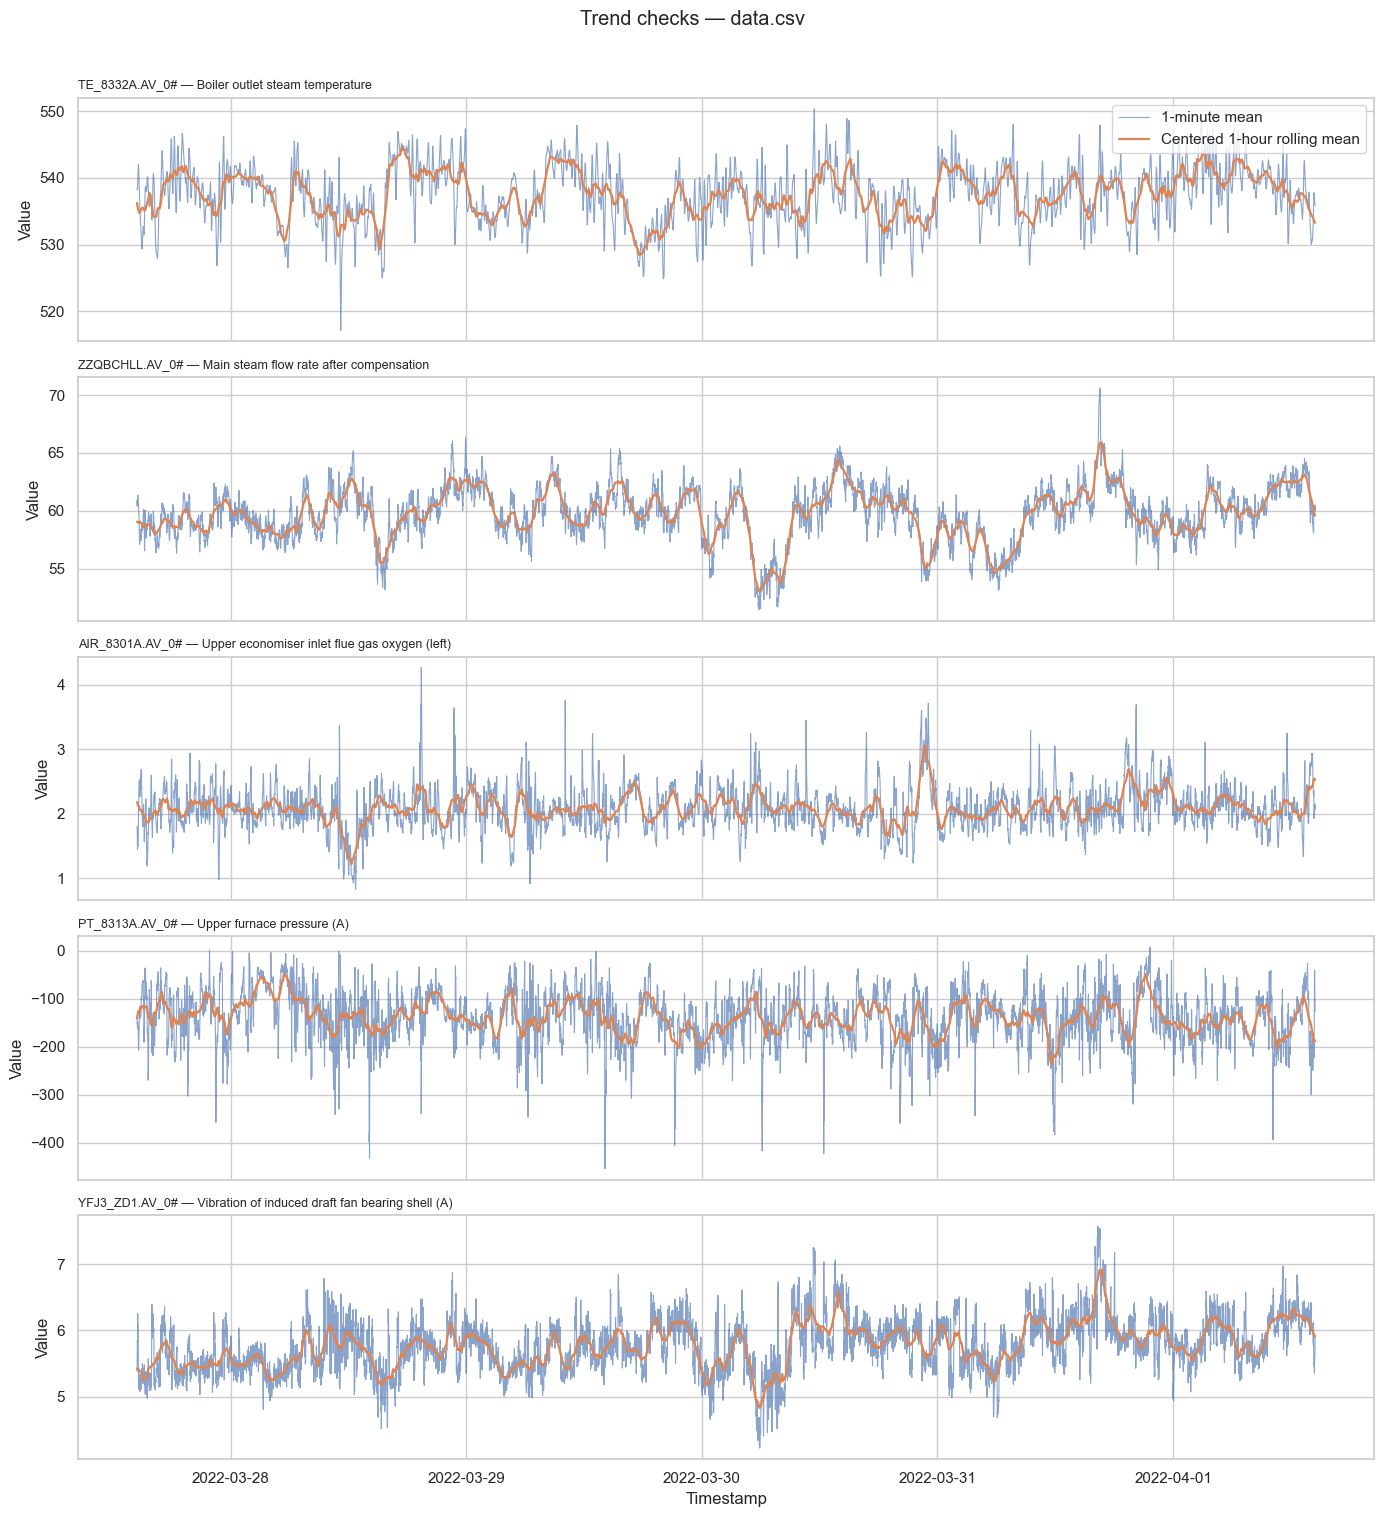

In [5]:
PLOT_DATASET = "data.csv"
plot_frame = minute_data if PLOT_DATASET == "data.csv" else minute_autoreg
preferred_sensors = [
    "TE_8332A.AV_0",  # boiler outlet steam temperature
    "ZZQBCHLL.AV_0",  # compensated main steam flow
    "AIR_8301A.AV_0", # economizer inlet flue gas oxygen
    "PT_8313A.AV_0",  # upper furnace pressure
    "YFJ3_ZD1.AV_0",  # induced draft fan bearing vibration
]
actual_sensor = {canonical_name(col): col for col in plot_frame.columns}
selected_sensors = [actual_sensor[key] for key in preferred_sensors if key in actual_sensor]
if not selected_sensors:
    selected_sensors = plot_frame.columns[:5].tolist()

if selected_sensors:
    fig, axes = plt.subplots(len(selected_sensors), 1,
                             figsize=(14, 3 * len(selected_sensors)), sharex=True)
    axes = np.atleast_1d(axes)
    for ax, col in zip(axes, selected_sensors):
        values = plot_frame[col].dropna()
        ax.plot(values.index, values, linewidth=.8, alpha=.65, label="1-minute mean")
        ax.plot(values.rolling("1h", min_periods=1, center=True).mean(),
                linewidth=1.6, label="Centered 1-hour rolling mean")
        label = metadata_map.get(canonical_name(col), "") or col
        ax.set_title(f"{col} — {label}", loc="left", fontsize=9)
        ax.set_ylabel("Value")
    axes[0].legend(loc="upper right")
    axes[-1].set_xlabel("Timestamp")
    fig.suptitle(f"Trend checks — {PLOT_DATASET}", y=1.01)
    plt.tight_layout()
    plt.show()
else:
    print("No numeric signals are available for trend plots.")

## 5. Quantify linear direction and within-day profiles

A fitted linear slope is a compact description over the observed span only. It can be misleading when operating regimes change, so it is accompanied by start/end means and a fitted-value range. The within-day profile averages observations at the same clock minute across available dates; incomplete daily coverage and short record duration limit seasonal interpretation.

### data.csv — descriptive linear trends


,sensor,measurement,slope_per_hour,fitted_change_over_span,first_block_mean,last_block_mean,observed_minutes
0,TE_8332A.AV_0#,Boiler outlet steam temperature,0.010173,1.220710,535.472833,534.879933,7201
1,ZZQBCHLL.AV_0#,Main steam flow rate after compensation,0.005723,0.686716,58.904306,61.281239,7201
2,AIR_8301A.AV_0#,Upper economiser inlet flue gas oxygen (left),0.000844,0.101338,2.039153,2.382997,7201
3,PT_8313A.AV_0#,Upper furnace pressure (A),-0.215434,-25.852066,-116.401972,-147.428483,7201
4,YFJ3_ZD1.AV_0#,Vibration of induced draft fan bearing shell (A),0.004221,0.506576,5.354569,6.048192,7201


### data_AutoReg.csv — descriptive linear trends


,sensor,measurement,slope_per_hour,fitted_change_over_span,first_block_mean,last_block_mean,observed_minutes
0,TE_8332A.AV_0#,Boiler outlet steam temperature,0.010173,1.220710,535.472833,534.879933,7201
1,ZZQBCHLL.AV_0#,Main steam flow rate after compensation,0.005723,0.686716,58.904306,61.281239,7201
2,AIR_8301A.AV_0#,Upper economiser inlet flue gas oxygen (left),0.000844,0.101338,2.039153,2.382997,7201
3,PT_8313A.AV_0#,Upper furnace pressure (A),-0.215434,-25.852066,-116.401972,-147.428483,7201
4,YFJ3_ZD1.AV_0#,Vibration of induced draft fan bearing shell (A),0.004221,0.506576,5.354569,6.048192,7201


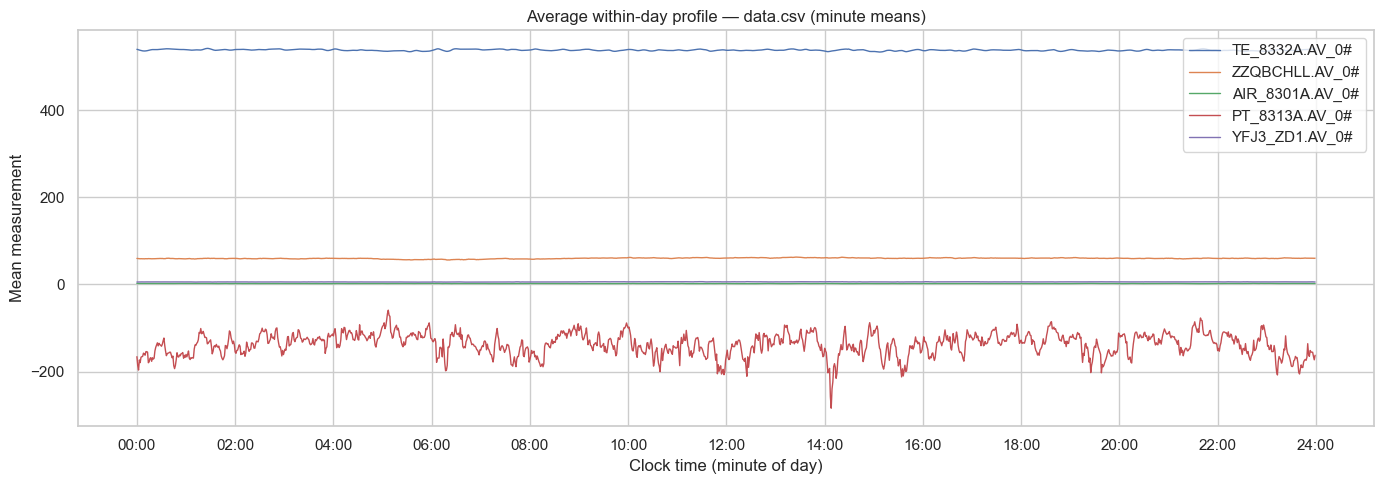

In [6]:
def trend_table(minute_frame, sensors):
    rows = []
    for col in sensors:
        series = minute_frame[col].dropna()
        if len(series) < 3:
            continue
        elapsed_hours = (series.index - series.index[0]).total_seconds() / 3600
        slope, intercept = np.polyfit(elapsed_hours, series.to_numpy(), 1)
        fitted = intercept + slope * elapsed_hours
        block = max(1, min(60, len(series) // 4))
        rows.append({
            "sensor": col,
            "measurement": metadata_map.get(canonical_name(col), "") or col,
            "slope_per_hour": slope,
            "fitted_change_over_span": fitted[-1] - fitted[0],
            "first_block_mean": series.iloc[:block].mean(),
            "last_block_mean": series.iloc[-block:].mean(),
            "observed_minutes": len(series),
        })
    return pd.DataFrame(rows)

trend_results = {}
for name, frame in (("data.csv", minute_data), ("data_AutoReg.csv", minute_autoreg)):
    available = [col for col in selected_sensors if col in frame.columns]
    table = trend_table(frame, available)
    trend_results[name] = table
    print(f"### {name} — descriptive linear trends")
    display(table if not table.empty else pd.DataFrame({"result": ["Insufficient observations"]}))

if not minute_data.empty and selected_sensors:
    profile_frame = minute_data[selected_sensors].copy()
    profile_frame["minute_of_day"] = profile_frame.index.hour * 60 + profile_frame.index.minute
    profile = profile_frame.groupby("minute_of_day")[selected_sensors].mean()
    fig, ax = plt.subplots(figsize=(14, 5))
    profile.plot(ax=ax, linewidth=1)
    ax.set(title="Average within-day profile — data.csv (minute means)",
           xlabel="Clock time (minute of day)", ylabel="Mean measurement")
    ax.set_xticks(np.arange(0, 1441, 120))
    ax.set_xticklabels([f"{hour:02d}:00" for hour in range(0, 25, 2)])
    plt.tight_layout()
    plt.show()

## 6. Autocorrelation and seasonal decomposition eligibility

Autocorrelation is computed from regular one-minute values after time interpolation for short gaps only; its peaks are descriptive evidence of repeated lag structure, not proof of a seasonal cause. STL decomposition is performed for a daily period only when there are at least two full daily cycles. Weekly STL is skipped unless at least two weekly cycles are observed. Given the short data coverage, longer-period claims are not justified.

data.csv / TE_8332A.AV_0#: autocorrelation at selected minute lags


,lag,period,autocorrelation
0,60,1 hour,0.264700
1,180,3 hours,0.049940
2,360,6 hours,-0.050151
3,720,12 hours,0.015856
4,1440,1 day,-0.064615
5,2880,2 days,-0.134036


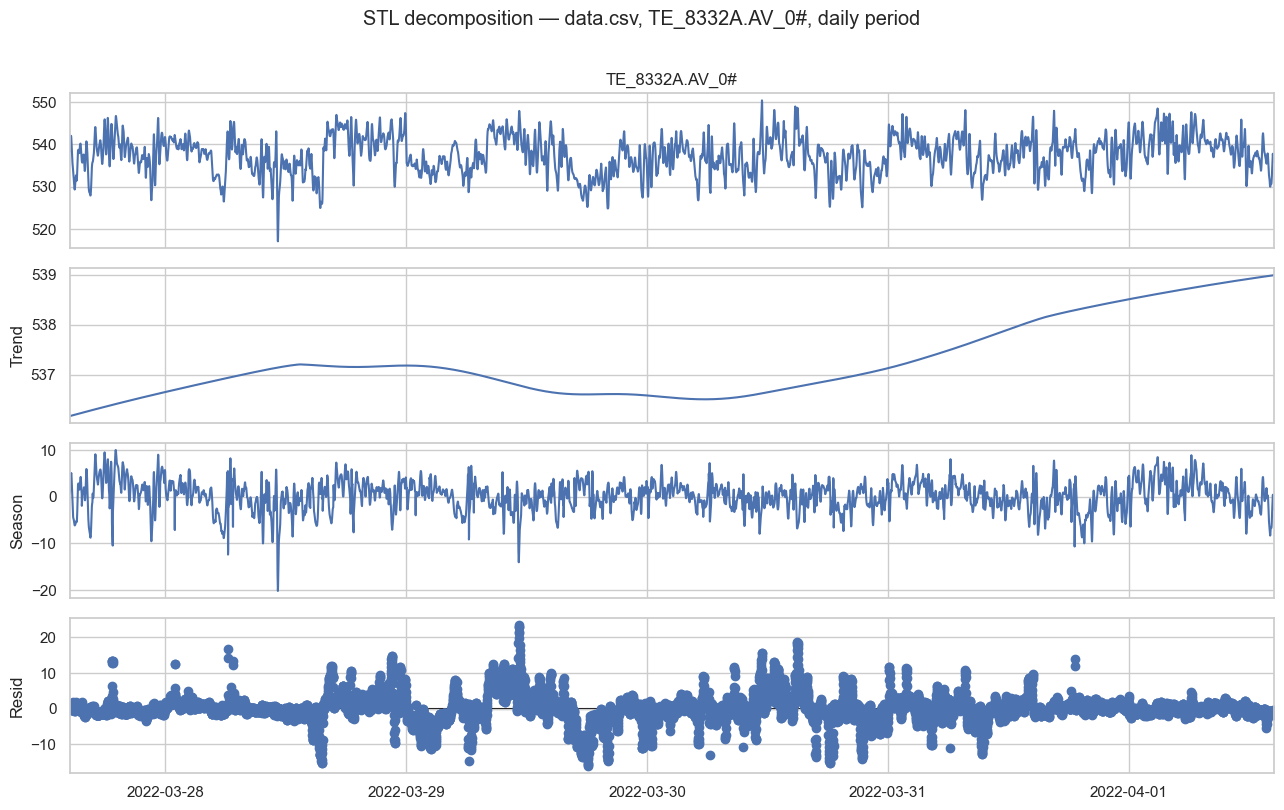

data.csv / TE_8332A.AV_0#: weekly STL skipped (0.71 cycles; need at least 2).
data.csv / ZZQBCHLL.AV_0#: autocorrelation at selected minute lags


,lag,period,autocorrelation
0,60,1 hour,0.509457
1,180,3 hours,0.090048
2,360,6 hours,-0.023695
3,720,12 hours,-0.133472
4,1440,1 day,0.143153
5,2880,2 days,0.030057


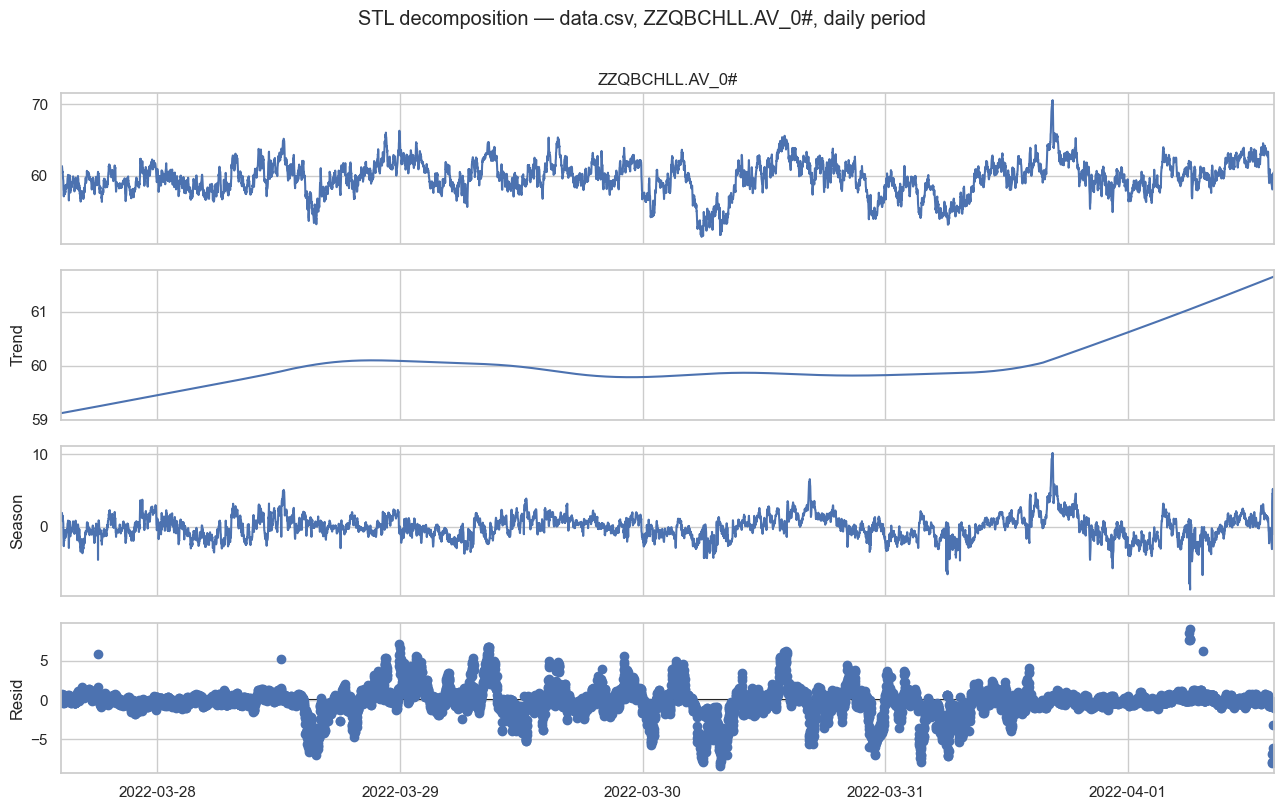

data.csv / ZZQBCHLL.AV_0#: weekly STL skipped (0.71 cycles; need at least 2).
data.csv / AIR_8301A.AV_0#: autocorrelation at selected minute lags


,lag,period,autocorrelation
0,60,1 hour,0.040421
1,180,3 hours,-0.007645
2,360,6 hours,0.009529
3,720,12 hours,-0.016565
4,1440,1 day,-0.000316
5,2880,2 days,0.024006


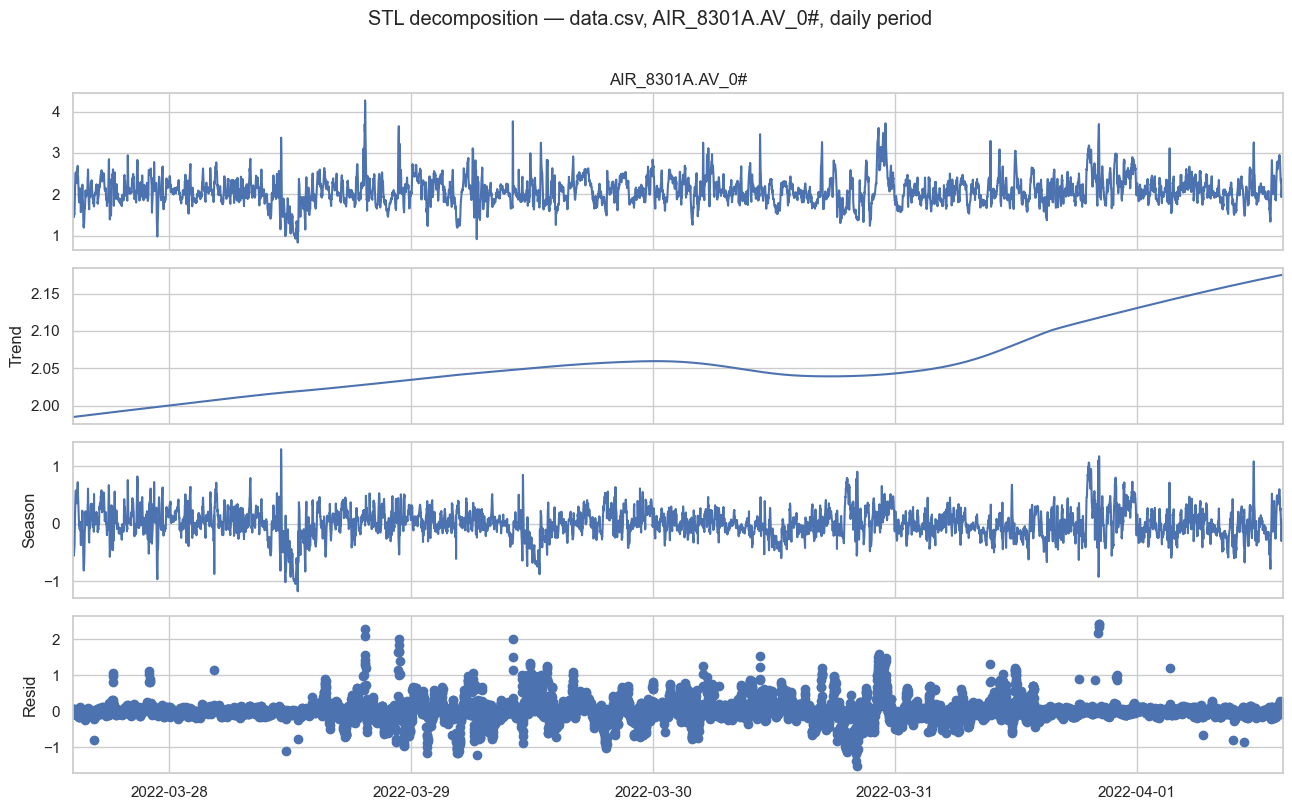

data.csv / AIR_8301A.AV_0#: weekly STL skipped (0.71 cycles; need at least 2).
data.csv / PT_8313A.AV_0#: autocorrelation at selected minute lags


,lag,period,autocorrelation
0,60,1 hour,0.075886
1,180,3 hours,0.016788
2,360,6 hours,-0.000036
3,720,12 hours,0.015749
4,1440,1 day,0.027074
5,2880,2 days,-0.016022


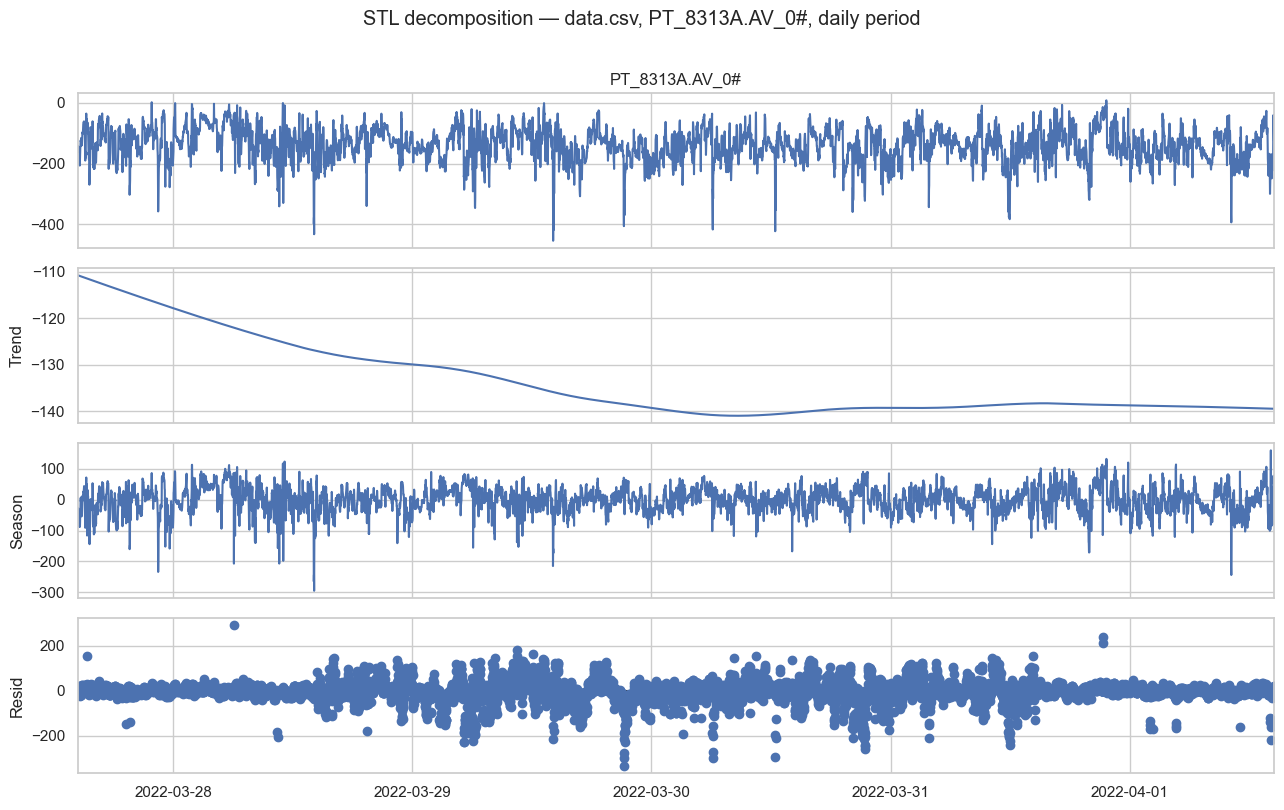

data.csv / PT_8313A.AV_0#: weekly STL skipped (0.71 cycles; need at least 2).
data.csv / YFJ3_ZD1.AV_0#: autocorrelation at selected minute lags


,lag,period,autocorrelation
0,60,1 hour,0.341824
1,180,3 hours,0.119833
2,360,6 hours,0.107087
3,720,12 hours,0.055017
4,1440,1 day,0.125370
5,2880,2 days,0.061068


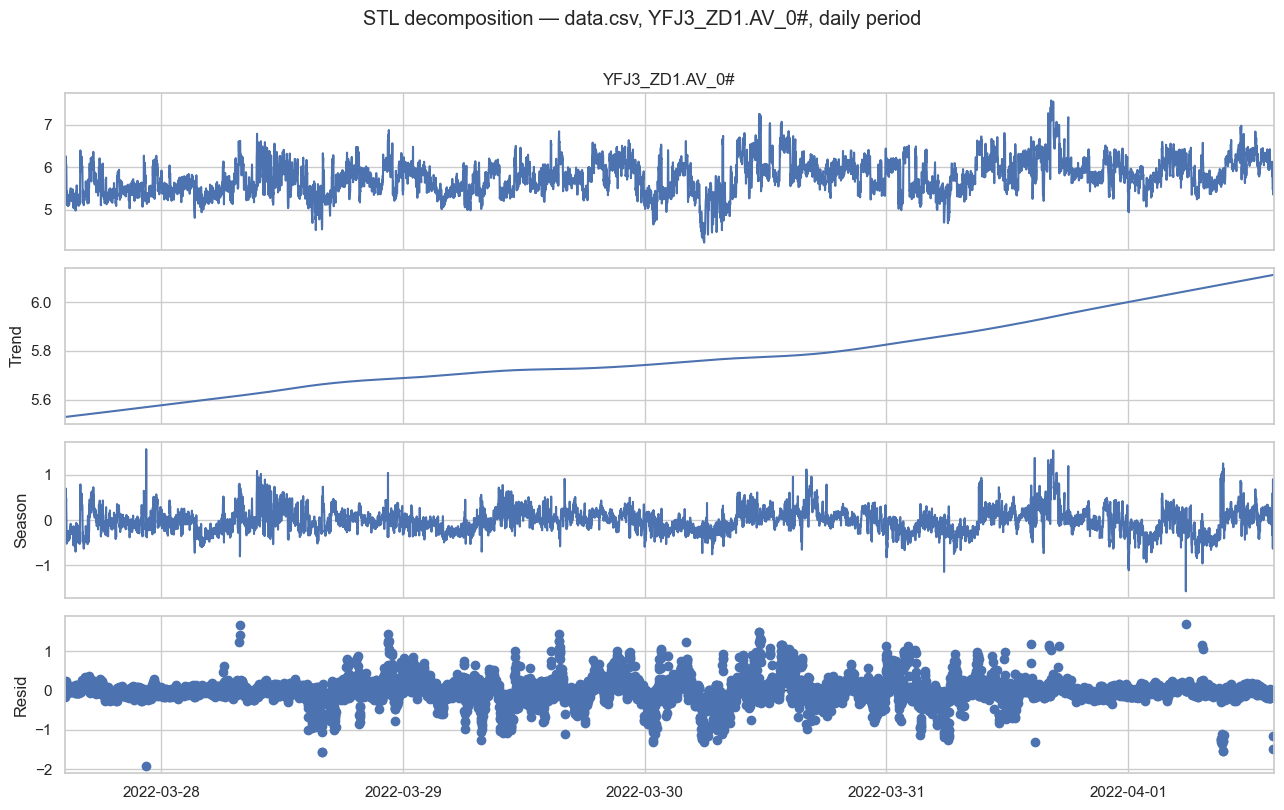

data.csv / YFJ3_ZD1.AV_0#: weekly STL skipped (0.71 cycles; need at least 2).
data_AutoReg.csv / TE_8332A.AV_0#: autocorrelation at selected minute lags


,lag,period,autocorrelation
0,60,1 hour,0.264700
1,180,3 hours,0.049940
2,360,6 hours,-0.050151
3,720,12 hours,0.015856
4,1440,1 day,-0.064615
5,2880,2 days,-0.134036


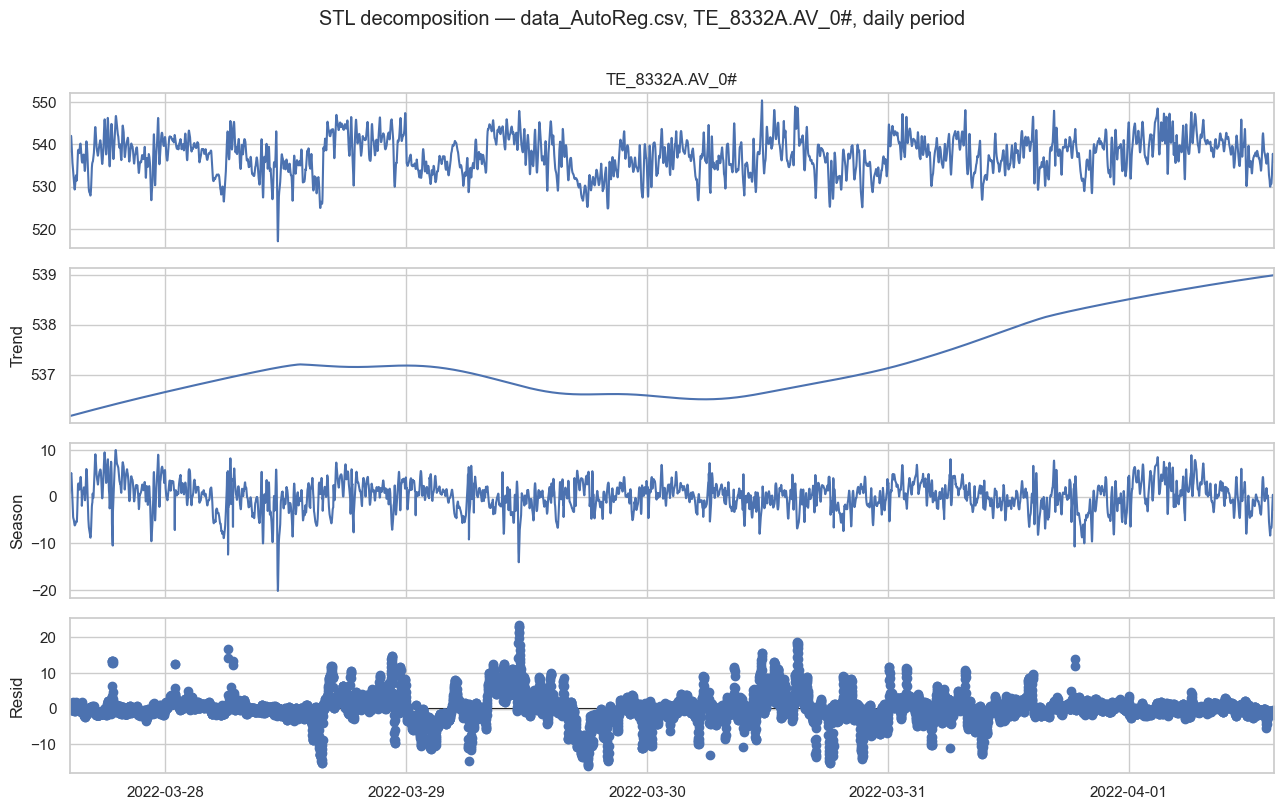

data_AutoReg.csv / TE_8332A.AV_0#: weekly STL skipped (0.71 cycles; need at least 2).
data_AutoReg.csv / ZZQBCHLL.AV_0#: autocorrelation at selected minute lags


,lag,period,autocorrelation
0,60,1 hour,0.509457
1,180,3 hours,0.090048
2,360,6 hours,-0.023695
3,720,12 hours,-0.133472
4,1440,1 day,0.143153
5,2880,2 days,0.030057


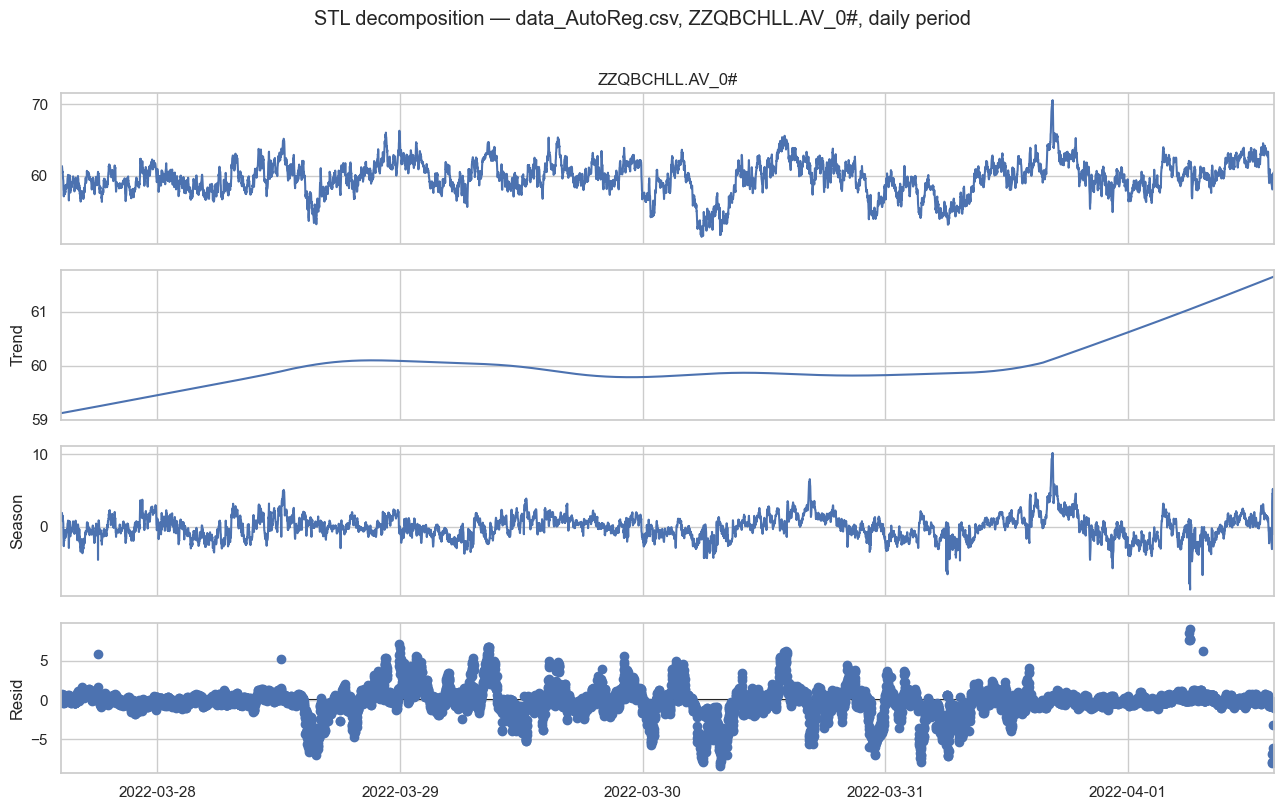

data_AutoReg.csv / ZZQBCHLL.AV_0#: weekly STL skipped (0.71 cycles; need at least 2).
data_AutoReg.csv / AIR_8301A.AV_0#: autocorrelation at selected minute lags


,lag,period,autocorrelation
0,60,1 hour,0.040421
1,180,3 hours,-0.007645
2,360,6 hours,0.009529
3,720,12 hours,-0.016565
4,1440,1 day,-0.000316
5,2880,2 days,0.024006


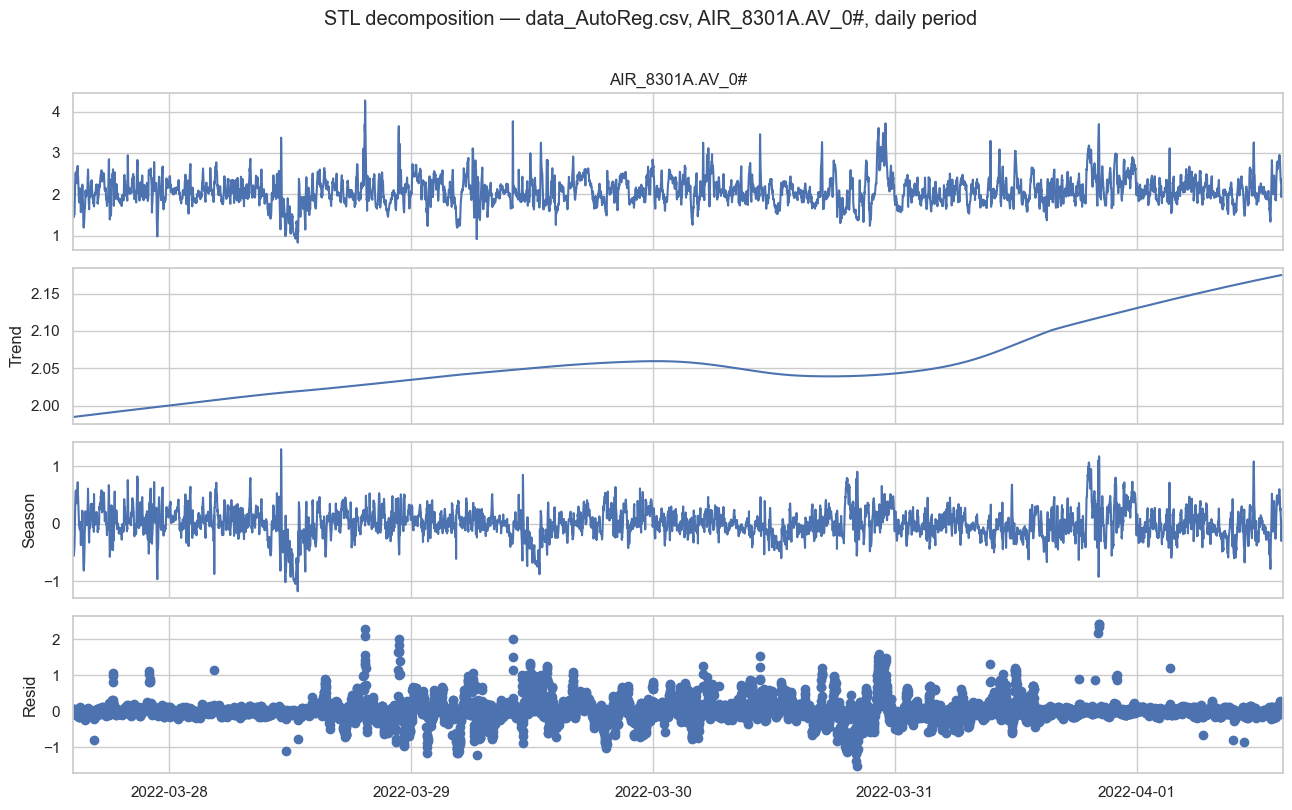

data_AutoReg.csv / AIR_8301A.AV_0#: weekly STL skipped (0.71 cycles; need at least 2).
data_AutoReg.csv / PT_8313A.AV_0#: autocorrelation at selected minute lags


,lag,period,autocorrelation
0,60,1 hour,0.075886
1,180,3 hours,0.016788
2,360,6 hours,-0.000036
3,720,12 hours,0.015749
4,1440,1 day,0.027074
5,2880,2 days,-0.016022


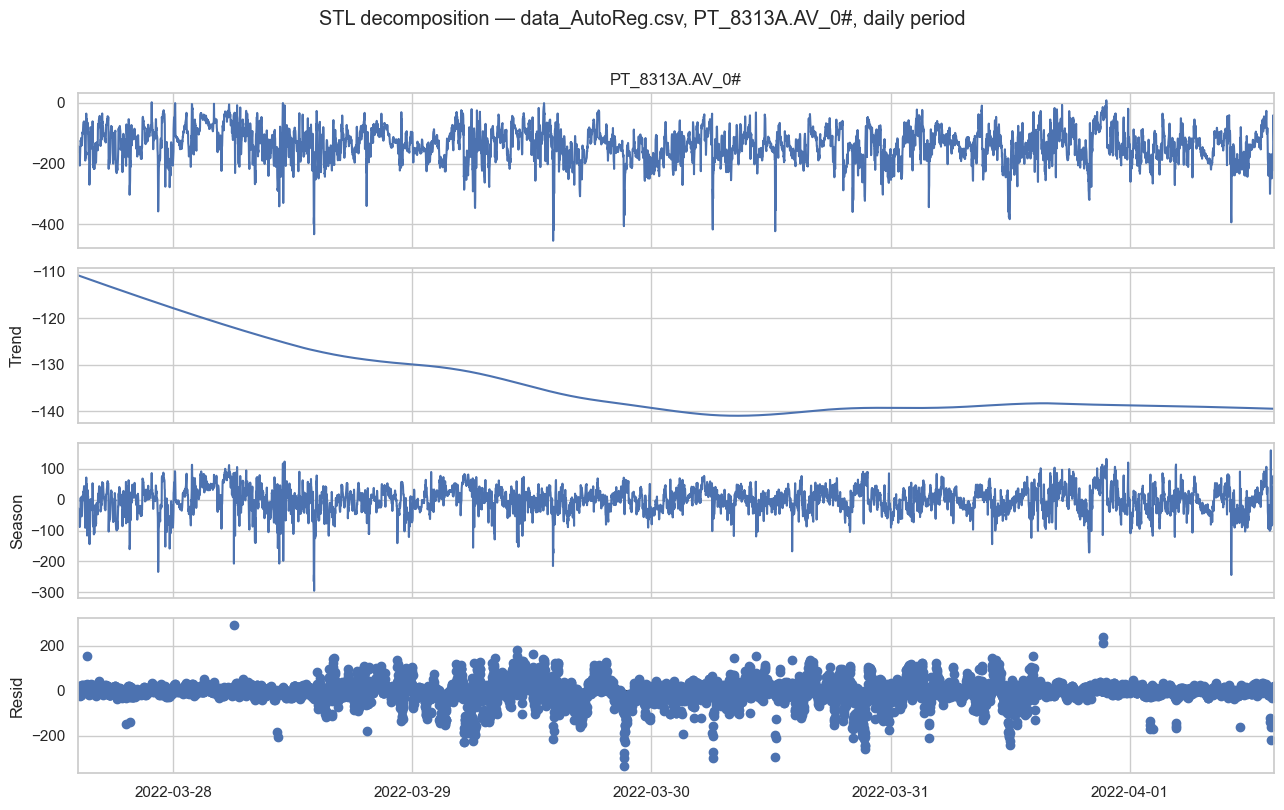

data_AutoReg.csv / PT_8313A.AV_0#: weekly STL skipped (0.71 cycles; need at least 2).
data_AutoReg.csv / YFJ3_ZD1.AV_0#: autocorrelation at selected minute lags


,lag,period,autocorrelation
0,60,1 hour,0.341824
1,180,3 hours,0.119833
2,360,6 hours,0.107087
3,720,12 hours,0.055017
4,1440,1 day,0.125370
5,2880,2 days,0.061068


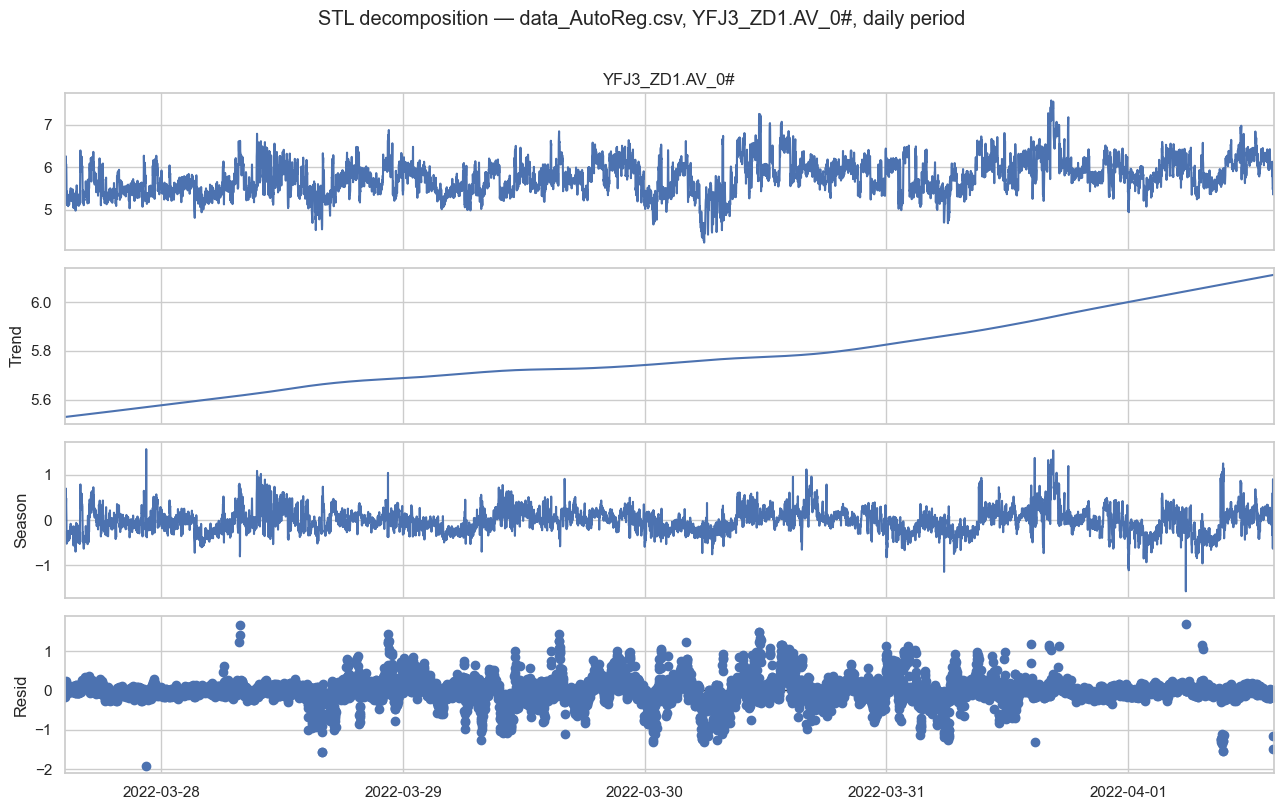

data_AutoReg.csv / YFJ3_ZD1.AV_0#: weekly STL skipped (0.71 cycles; need at least 2).


In [7]:
try:
    from statsmodels.tsa.seasonal import STL
    from statsmodels.tsa.stattools import acf
    STATSMODELS_AVAILABLE = True
except ImportError as error:
    warnings.warn(f"statsmodels is unavailable; autocorrelation and STL checks are skipped: {error}")
    STATSMODELS_AVAILABLE = False

stl_results = {}
acf_results = {}
if STATSMODELS_AVAILABLE:
    for name, frame in (("data.csv", minute_data), ("data_AutoReg.csv", minute_autoreg)):
        info = time_info.get(name)
        if not info or frame.empty:
            print(f"{name}: insufficient valid timestamped data for periodic analysis.")
            continue
        available_sensors = [col for col in selected_sensors if col in frame.columns]
        for col in available_sensors:
            values = frame[col].asfreq("1min")
            values = values.interpolate(method="time", limit=5, limit_area="inside").dropna()
            if len(values) < 10:
                continue
            lags = min(7 * 24 * 60, len(values) // 2 - 1)
            if lags >= 1:
                acf_values = acf(values, nlags=lags, fft=True, missing="drop")
                acf_results[(name, col)] = acf_values
                lag_candidates = {60: "1 hour", 180: "3 hours", 360: "6 hours", 720: "12 hours", 1440: "1 day", 2880: "2 days", 10080: "1 week"}
                print(f"{name} / {col}: autocorrelation at selected minute lags")
                display(pd.DataFrame([
                    {"lag": lag, "period": label, "autocorrelation": acf_values[lag]}
                    for lag, label in lag_candidates.items() if lag < len(acf_values)
                ]))

            for period, label in ((1440, "daily"), (10080, "weekly")):
                cycle_count = len(values) / period
                if cycle_count < 2:
                    print(f"{name} / {col}: {label} STL skipped ({cycle_count:.2f} cycles; need at least 2).")
                    continue
                result = STL(values, period=period, robust=True).fit()
                stl_results[(name, col, label)] = result
                fig = result.plot()
                fig.set_size_inches(13, 8)
                fig.suptitle(f"STL decomposition — {name}, {col}, {label} period", y=1.01)
                plt.tight_layout()
                plt.show()
else:
    print("Install statsmodels in the selected notebook environment to enable ACF and STL analyses.")

## 7. Compare datasets and summarize conclusions

Compare minute-aggregated shared sensors at matched timestamps, alongside trend slopes for signals present in both files. Conclusions should account for preprocessing differences, process state, and the short observation window. A lack of a detectable cycle in a five-day window does not demonstrate that the process has no seasonality.

In [ ]:
shared_keys = sorted(
    {canonical_name(col) for col in minute_data.columns}
    & {canonical_name(col) for col in minute_autoreg.columns}
)
left_names = {canonical_name(col): col for col in minute_data.columns}
right_names = {canonical_name(col): col for col in minute_autoreg.columns}
comparison_rows = []
if shared_keys:
    left = minute_data[[left_names[key] for key in shared_keys]].copy()
    right = minute_autoreg[[right_names[key] for key in shared_keys]].copy()
    left.columns = shared_keys
    right.columns = shared_keys
    paired = left.join(right, how="inner", lsuffix="_data", rsuffix="_autoreg")
    print(f"Shared measurement columns: {len(shared_keys)}; matched minute timestamps: {len(paired):,}")
    for key in shared_keys:
        x, y = paired[f"{key}_data"], paired[f"{key}_autoreg"]
        valid = x.notna() & y.notna()
        if not valid.any():
            continue
        comparison_rows.append({
            "sensor": key,
            "measurement": metadata_map.get(key, "") or key,
            "matched_minutes": int(valid.sum()),
            "mean_absolute_difference": (x[valid] - y[valid]).abs().mean(),
            "correlation": x[valid].corr(y[valid]) if valid.sum() > 1 else np.nan,
        })
    comparison = pd.DataFrame(comparison_rows)
    display(comparison.sort_values("mean_absolute_difference", ascending=False).head(15)
            if not comparison.empty else pd.DataFrame({"result": ["No paired numeric measurements"]}))
else:
    paired = pd.DataFrame()
    print("No shared numeric measurements were found for dataset comparison.")

print("\n### Summary and interpretation")
for name, info in time_info.items():
    if info:
        days = info["span"].total_seconds() / 86400
        print(f"{name}: {days:.2f} days of observations; sufficient for a repeated daily pattern check: {days >= 2}.")
        print(f"  Sufficient for a repeated weekly pattern check: {days >= 14}.")
for name, table in trend_results.items():
    if not table.empty:
        direction = ("increasing" if (table.slope_per_hour > 0).any() else
                     "decreasing" if (table.slope_per_hour < 0).any() else "approximately flat")
        print(f"{name}: selected-sensor fitted trends include an overall {direction} direction; "
              "inspect sensor-level slopes and plots for exceptions.")

print("\nLimitations: linear slopes summarize only this observation window; minute averaging hides sub-minute transients; "
      "daily profiles can be affected by startups, shutdowns, load changes, and missing intervals. "
      "The available short record cannot verify weekly or annual seasonality. These results are descriptive and non-causal.")